#Opportunity Insights and ELS Exploratory Analysis
This notebook explores the relationship between family
socioeconomic background and later outcomes using
Opportunity Insights and ELS data.

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load ELS datasets
els_a = pd.read_csv("data/raw/els/sophomorefinances2a.csv")
els_b = pd.read_csv("data/raw/els/sophomorefinances2b.csv")

# Load Opportunity Insights dataset
oi = pd.read_excel("data/raw/opportunity_insights/gender_nat.xls")

# Preview datasets
display(els_a.head())
display(els_b.head())
display(oi.head())

,"2012 labor force participation and employment intensity of 2002 high school sophomores with Associate's Degree or Higher as of 2012, by parents' 2002 socioeconomic status",Unnamed: 1,Unnamed: 2,Unnamed: 3
0,NaN,Parents' SES,NaN,NaN
1,Current employment status,Low,Middle,High
2,Unemployed,9.1,5.5,5.2
3,Out-of-the-labor force,4.5,4.3,7.4
4,Working 0-34 hours/week,12.8,11.8,10.9


,"2012 labor force participation and employment intensity of 2002 high school sophomores with Bachelor's Degree or Higher as of 2012, by parents' 2002 socioeconomic status",Unnamed: 1,Unnamed: 2,Unnamed: 3
0,NaN,Parents' SES,NaN,NaN
1,Current employment status,Low,Middle,High
2,Unemployed,8.4,4.7,4.9
3,Out-of-the-labor force,4.8,4.1,7.4
4,Working 0-34 hours/week,10.8,11.1,10.5


,par_pctile,w2_or_sc_nz_30_f,w2_or_sc_nz_30_m,w2_pos_30_f,w2_pos_30_m,w2_or_sc_nz_30_f_sp,w2_or_sc_nz_30_m_sp,w2_pos_30_f_sp,w2_pos_30_m_sp,w2_or_sc_nz_30_f_tp,...,coll1823_f,coll1823_m,kid_indv_rank_26_f,kid_indv_rank_26_m,kid_indv_rank_30_f,kid_indv_rank_30_m,kid_rank_30_f,kid_rank_30_m,w2wages_30_f,w2wages_30_m
0,1,0.701873,0.619219,0.634008,0.581318,0.703665,0.601713,0.635264,0.566462,0.694450,...,0.438878,0.291378,0.332737,0.331721,0.331520,0.328640,0.320086,0.282094,20034.866784,24414.304218
1,2,0.722179,0.651330,0.655950,0.616341,0.726418,0.634450,0.659641,0.602562,0.706608,...,0.449289,0.295981,0.345648,0.349095,0.342581,0.348854,0.333741,0.300275,20437.471764,26142.301851
2,3,0.736015,0.668702,0.671580,0.631375,0.739409,0.651729,0.674606,0.618084,0.724647,...,0.459616,0.302422,0.352988,0.361581,0.349441,0.358980,0.344360,0.308929,20642.048536,25736.815017
3,4,0.744418,0.687326,0.680913,0.652771,0.747730,0.671441,0.685144,0.640212,0.734008,...,0.467593,0.313595,0.358757,0.369839,0.356087,0.370133,0.352396,0.318354,21004.724787,26099.303301
4,5,0.756787,0.696942,0.694531,0.658317,0.760913,0.679759,0.700141,0.645505,0.744631,...,0.477522,0.320263,0.364045,0.375643,0.363434,0.375367,0.360338,0.324334,21515.289483,27079.109686


In [11]:
for name, df in [
    ("ELS A", els_a),
    ("ELS B", els_b),
    ("Opportunity Insights", oi)
]:
    print(f"\n{name}")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head())


ELS A
Shape: (7, 4)
Columns: ["2012 labor force participation and employment intensity of 2002 high school sophomores with Associate's Degree or Higher as of 2012, by parents' 2002 socioeconomic status ", 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3']


,"2012 labor force participation and employment intensity of 2002 high school sophomores with Associate's Degree or Higher as of 2012, by parents' 2002 socioeconomic status",Unnamed: 1,Unnamed: 2,Unnamed: 3
0,NaN,Parents' SES,NaN,NaN
1,Current employment status,Low,Middle,High
2,Unemployed,9.1,5.5,5.2
3,Out-of-the-labor force,4.5,4.3,7.4
4,Working 0-34 hours/week,12.8,11.8,10.9



ELS B
Shape: (7, 4)
Columns: ["2012 labor force participation and employment intensity of 2002 high school sophomores with Bachelor's Degree or Higher as of 2012, by parents' 2002 socioeconomic status", 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3']


,"2012 labor force participation and employment intensity of 2002 high school sophomores with Bachelor's Degree or Higher as of 2012, by parents' 2002 socioeconomic status",Unnamed: 1,Unnamed: 2,Unnamed: 3
0,NaN,Parents' SES,NaN,NaN
1,Current employment status,Low,Middle,High
2,Unemployed,8.4,4.7,4.9
3,Out-of-the-labor force,4.8,4.1,7.4
4,Working 0-34 hours/week,10.8,11.1,10.5



Opportunity Insights
Shape: (100, 25)
Columns: ['par_pctile', 'w2_or_sc_nz_30_f', 'w2_or_sc_nz_30_m', 'w2_pos_30_f', 'w2_pos_30_m', 'w2_or_sc_nz_30_f_sp', 'w2_or_sc_nz_30_m_sp', 'w2_pos_30_f_sp', 'w2_pos_30_m_sp', 'w2_or_sc_nz_30_f_tp', 'w2_or_sc_nz_30_m_tp', 'w2_pos_30_f_tp', 'w2_pos_30_m_tp', 'w2_nonemp_f', 'w2_nonemp_m', 'coll1823_f', 'coll1823_m', 'kid_indv_rank_26_f', 'kid_indv_rank_26_m', 'kid_indv_rank_30_f', 'kid_indv_rank_30_m', 'kid_rank_30_f', 'kid_rank_30_m', 'w2wages_30_f', 'w2wages_30_m']


,par_pctile,w2_or_sc_nz_30_f,w2_or_sc_nz_30_m,w2_pos_30_f,w2_pos_30_m,w2_or_sc_nz_30_f_sp,w2_or_sc_nz_30_m_sp,w2_pos_30_f_sp,w2_pos_30_m_sp,w2_or_sc_nz_30_f_tp,...,coll1823_f,coll1823_m,kid_indv_rank_26_f,kid_indv_rank_26_m,kid_indv_rank_30_f,kid_indv_rank_30_m,kid_rank_30_f,kid_rank_30_m,w2wages_30_f,w2wages_30_m
0,1,0.701873,0.619219,0.634008,0.581318,0.703665,0.601713,0.635264,0.566462,0.694450,...,0.438878,0.291378,0.332737,0.331721,0.331520,0.328640,0.320086,0.282094,20034.866784,24414.304218
1,2,0.722179,0.651330,0.655950,0.616341,0.726418,0.634450,0.659641,0.602562,0.706608,...,0.449289,0.295981,0.345648,0.349095,0.342581,0.348854,0.333741,0.300275,20437.471764,26142.301851
2,3,0.736015,0.668702,0.671580,0.631375,0.739409,0.651729,0.674606,0.618084,0.724647,...,0.459616,0.302422,0.352988,0.361581,0.349441,0.358980,0.344360,0.308929,20642.048536,25736.815017
3,4,0.744418,0.687326,0.680913,0.652771,0.747730,0.671441,0.685144,0.640212,0.734008,...,0.467593,0.313595,0.358757,0.369839,0.356087,0.370133,0.352396,0.318354,21004.724787,26099.303301
4,5,0.756787,0.696942,0.694531,0.658317,0.760913,0.679759,0.700141,0.645505,0.744631,...,0.477522,0.320263,0.364045,0.375643,0.363434,0.375367,0.360338,0.324334,21515.289483,27079.109686


In [12]:
def clean_els(df):
    # Remove the title and header rows
    cleaned = df.iloc[2:].copy()

    # Rename columns
    cleaned.columns = [
        "Employment Status",
        "Low SES",
        "Middle SES",
        "High SES"
    ]

    # Convert percentages to numbers
    for col in ["Low SES", "Middle SES", "High SES"]:
        cleaned[col] = pd.to_numeric(cleaned[col], errors="coerce")

    return cleaned.reset_index(drop=True)

els_a_clean = clean_els(els_a)
els_b_clean = clean_els(els_b)

display(els_a_clean)
display(els_b_clean)

,Employment Status,Low SES,Middle SES,High SES
0,Unemployed,9.1,5.5,5.2
1,Out-of-the-labor force,4.5,4.3,7.4
2,Working 0-34 hours/week,12.8,11.8,10.9
3,Working 35+ hours/week,73.6,78.4,76.4
4,Source: Education Longitudinal Study of 2002 (...,NaN,NaN,NaN


,Employment Status,Low SES,Middle SES,High SES
0,Unemployed,8.4,4.7,4.9
1,Out-of-the-labor force,4.8,4.1,7.4
2,Working 0-34 hours/week,10.8,11.1,10.5
3,Working 35+ hours/week,76.0,80.1,77.2
4,Source: Education Longitudinal Study of 2002 (...,NaN,NaN,NaN


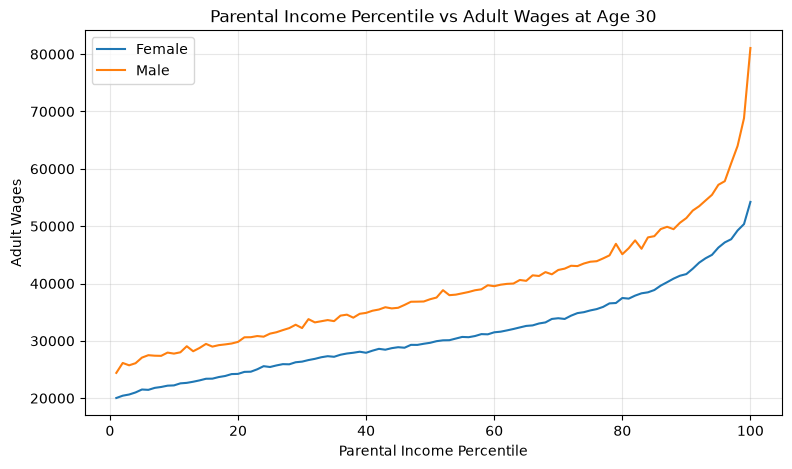

In [13]:
plt.figure(figsize=(9, 5))

sns.lineplot(
    data=oi,
    x="par_pctile",
    y="w2wages_30_f",
    label="Female"
)

sns.lineplot(
    data=oi,
    x="par_pctile",
    y="w2wages_30_m",
    label="Male"
)

plt.title("Parental Income Percentile vs Adult Wages at Age 30")
plt.xlabel("Parental Income Percentile")
plt.ylabel("Adult Wages")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Opportunity Insights: Parental Income and Adult Wages

This graph compares parental income percentile with adult
wages at age 30 for males and females.

**So what?**
This helps us understand how family economic background
is associated with earnings later in life.

**Expected or unexpected?**
We expect individuals from higher-income families to
generally have higher earnings as adults. The graph
will help us determine whether this pattern appears
in the data.

**What next?**
We can compare these results with employment patterns
in the ELS datasets and with our primary datasets.

### Opportunity Insights: Parental Income vs. Adult Wages

The graph shows a positive relationship between parental income and adult wages at age 30. As parental income percentile increases, adult wages generally increase for both men and women. Men also consistently have higher wages than women, with the gap becoming larger at higher parental income percentiles.

**So what?** This suggests that family income is associated with economic outcomes later in life. Even though wages increase for both groups, the difference between men and women shows that gender may also play a role in adult earnings.

**Expected or unexpected?** I expected people from higher-income families to have higher wages as adults, but I was surprised by how sharply wages increased at the highest parental income percentiles, especially for men.

**What next?** We could compare these findings with our primary datasets to see whether they show similar relationships between family background and adult earnings. We could also investigate whether education helps explain some of these differences.

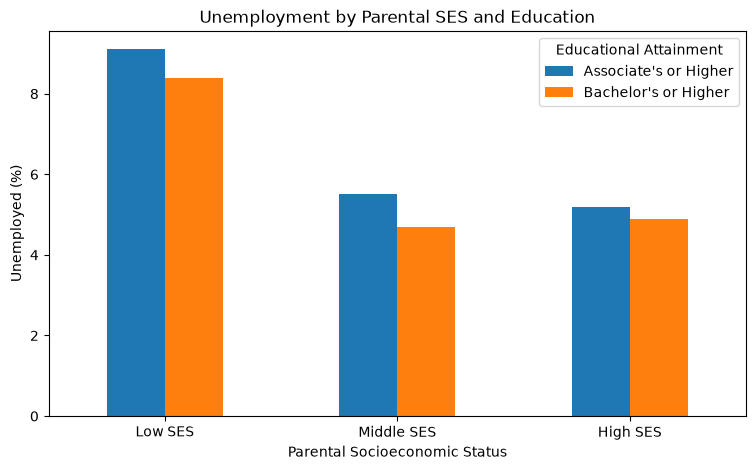

In [14]:
# Select unemployment row
a_unemployed = els_a_clean[
    els_a_clean["Employment Status"] == "Unemployed"
].iloc[0]

b_unemployed = els_b_clean[
    els_b_clean["Employment Status"] == "Unemployed"
].iloc[0]

ses = ["Low SES", "Middle SES", "High SES"]

comparison = pd.DataFrame({
    "Parent SES": ses,
    "Associate's or Higher": [a_unemployed[s] for s in ses],
    "Bachelor's or Higher": [b_unemployed[s] for s in ses]
})

comparison.plot(
    x="Parent SES",
    kind="bar",
    figsize=(9, 5)
)

plt.title("Unemployment by Parental SES and Education")
plt.xlabel("Parental Socioeconomic Status")
plt.ylabel("Unemployed (%)")
plt.xticks(rotation=0)
plt.legend(title="Educational Attainment")
plt.show()

### ELS: Unemployment by Parental SES and Education

The graph compares unemployment percentages across three parental socioeconomic groups for people with an associate's degree or higher and those with a bachelor's degree or higher.

The low-SES group has the highest unemployment percentage in both education categories. For example, among people with a bachelor's degree or higher, unemployment is 8.4% for the low-SES group compared to 4.9% for the high-SES group. The differences between the middle- and high-SES groups are much smaller.

**So what?** This suggests that family socioeconomic background may still be associated with employment outcomes even among people who have completed higher education.

**Expected or unexpected?** I expected unemployment to be lower among people with higher educational attainment, but I found it interesting that the low-SES group still had noticeably higher unemployment in both categories.

**What next?** We could compare these findings with our primary datasets to see whether parental socioeconomic status has a similar relationship with employment. We could also investigate whether other factors, such as educational attainment or demographic characteristics, help explain these differences.


In [15]:
for name, df in [
    ("ELS A", els_a_clean),
    ("ELS B", els_b_clean),
    ("Opportunity Insights", oi)
]:
    print(f"\n{name}")
    print("Shape:", df.shape)

    print("\nMissing values:")
    print(df.isnull().sum().to_string())

    print("\nDuplicate rows:", df.duplicated().sum())

    print("\nSummary statistics:")
    display(df.describe(include="all"))


ELS A
Shape: (5, 4)

Missing values:
Employment Status    0
Low SES              1
Middle SES           1
High SES             1

Duplicate rows: 0

Summary statistics:


,Employment Status,Low SES,Middle SES,High SES
count,5,4.000000,4.000000,4.000000
unique,5,NaN,NaN,NaN
top,Unemployed,NaN,NaN,NaN
freq,1,NaN,NaN,NaN
mean,NaN,25.000000,25.000000,24.975000
std,NaN,32.577395,35.751643,34.363583
min,NaN,4.500000,4.300000,5.200000
25%,NaN,7.950000,5.200000,6.850000
50%,NaN,10.950000,8.650000,9.150000
75%,NaN,28.000000,28.450000,27.275000



ELS B
Shape: (5, 4)

Missing values:
Employment Status    0
Low SES              1
Middle SES           1
High SES             1

Duplicate rows: 0

Summary statistics:


,Employment Status,Low SES,Middle SES,High SES
count,5,4.000000,4.00000,4.000000
unique,5,NaN,NaN,NaN
top,Unemployed,NaN,NaN,NaN
freq,1,NaN,NaN,NaN
mean,NaN,25.000000,25.00000,25.000000
std,NaN,34.089295,36.86968,34.875302
min,NaN,4.800000,4.10000,4.900000
25%,NaN,7.500000,4.55000,6.775000
50%,NaN,9.600000,7.90000,8.950000
75%,NaN,27.100000,28.35000,27.175000



Opportunity Insights
Shape: (100, 25)

Missing values:
par_pctile             0
w2_or_sc_nz_30_f       0
w2_or_sc_nz_30_m       0
w2_pos_30_f            0
w2_pos_30_m            0
w2_or_sc_nz_30_f_sp    0
w2_or_sc_nz_30_m_sp    0
w2_pos_30_f_sp         0
w2_pos_30_m_sp         0
w2_or_sc_nz_30_f_tp    0
w2_or_sc_nz_30_m_tp    0
w2_pos_30_f_tp         0
w2_pos_30_m_tp         0
w2_nonemp_f            0
w2_nonemp_m            0
coll1823_f             0
coll1823_m             0
kid_indv_rank_26_f     0
kid_indv_rank_26_m     0
kid_indv_rank_30_f     0
kid_indv_rank_30_m     0
kid_rank_30_f          0
kid_rank_30_m          0
w2wages_30_f           0
w2wages_30_m           0

Duplicate rows: 0

Summary statistics:


,par_pctile,w2_or_sc_nz_30_f,w2_or_sc_nz_30_m,w2_pos_30_f,w2_pos_30_m,w2_or_sc_nz_30_f_sp,w2_or_sc_nz_30_m_sp,w2_pos_30_f_sp,w2_pos_30_m_sp,w2_or_sc_nz_30_f_tp,...,coll1823_f,coll1823_m,kid_indv_rank_26_f,kid_indv_rank_26_m,kid_indv_rank_30_f,kid_indv_rank_30_m,kid_rank_30_f,kid_rank_30_m,w2wages_30_f,w2wages_30_m
count,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,...,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000
mean,50.500000,0.827979,0.833813,0.779421,0.801460,0.825741,0.799269,0.779602,0.769002,0.823241,...,0.736535,0.616320,0.481571,0.518886,0.472440,0.528164,0.517690,0.483509,31211.763414,39048.858804
std,29.011492,0.039772,0.068046,0.045622,0.070644,0.031709,0.057302,0.037180,0.057187,0.045475,...,0.154494,0.196401,0.074175,0.077840,0.072758,0.089186,0.097243,0.094696,7570.090145,10086.738256
min,1.000000,0.701873,0.619219,0.634008,0.581318,0.703665,0.601713,0.635264,0.566462,0.694450,...,0.438878,0.291378,0.332737,0.331721,0.331520,0.328640,0.320086,0.282094,20034.866784,24414.304218
25%,25.750000,0.803876,0.788567,0.753064,0.755430,0.811278,0.763895,0.765286,0.737318,0.790389,...,0.611006,0.447357,0.423572,0.457219,0.418153,0.456467,0.438290,0.405872,25681.466709,31441.570326
50%,50.500000,0.830862,0.856743,0.784345,0.825008,0.835973,0.818238,0.793787,0.787581,0.828595,...,0.741247,0.607624,0.477816,0.535983,0.464557,0.538782,0.522200,0.493917,29802.483527,37408.954874
75%,75.250000,0.861266,0.890474,0.817354,0.861294,0.845916,0.843502,0.805431,0.809855,0.861906,...,0.873517,0.782540,0.541842,0.587663,0.526576,0.602530,0.597736,0.561321,35364.066829,43821.797094
max,100.000000,0.883353,0.906234,0.842484,0.875843,0.877086,0.868762,0.831563,0.837887,0.884689,...,0.969784,0.954586,0.614812,0.631311,0.615525,0.678782,0.681686,0.648746,54231.843767,81073.710454


In [16]:
print("ELS A missing rows:")
display(els_a_clean[els_a_clean.isnull().any(axis=1)])

print("ELS B missing rows:")
display(els_b_clean[els_b_clean.isnull().any(axis=1)])

ELS A missing rows:


,Employment Status,Low SES,Middle SES,High SES
4,Source: Education Longitudinal Study of 2002 (...,NaN,NaN,NaN


ELS B missing rows:


,Employment Status,Low SES,Middle SES,High SES
4,Source: Education Longitudinal Study of 2002 (...,NaN,NaN,NaN


In [17]:
# Remove source citation rows
els_a_clean = els_a_clean[
    ~els_a_clean["Employment Status"].str.startswith("Source:", na=False)
].reset_index(drop=True)

els_b_clean = els_b_clean[
    ~els_b_clean["Employment Status"].str.startswith("Source:", na=False)
].reset_index(drop=True)

# Check results
print("ELS A:")
display(els_a_clean)

print("\nELS B:")
display(els_b_clean)

print("\nMissing values:")
print(els_a_clean.isnull().sum())
print(els_b_clean.isnull().sum())

ELS A:


,Employment Status,Low SES,Middle SES,High SES
0,Unemployed,9.1,5.5,5.2
1,Out-of-the-labor force,4.5,4.3,7.4
2,Working 0-34 hours/week,12.8,11.8,10.9
3,Working 35+ hours/week,73.6,78.4,76.4



ELS B:


,Employment Status,Low SES,Middle SES,High SES
0,Unemployed,8.4,4.7,4.9
1,Out-of-the-labor force,4.8,4.1,7.4
2,Working 0-34 hours/week,10.8,11.1,10.5
3,Working 35+ hours/week,76.0,80.1,77.2



Missing values:
Employment Status    0
Low SES              0
Middle SES           0
High SES             0
dtype: int64
Employment Status    0
Low SES              0
Middle SES           0
High SES             0
dtype: int64


### ELS Data Cleaning and Anomalies

Both ELS datasets initially appeared to have three missing values, one in each parental SES column. After checking the rows, I found that these missing values came from a source citation at the bottom of each table rather than actual employment data.

I removed the source rows because they weren't part of the observations being analyzed. After cleaning, both datasets contained four employment categories and three parental SES groups, with no missing values or duplicates.

The employment values are percentages, and the tables contain aggregated group statistics rather than individual student records.

In [18]:
for name, df in [
    ("ELS A", els_a_clean),
    ("ELS B", els_b_clean)
]:
    print(f"\n{name} percentage totals:")
    print(df[["Low SES", "Middle SES", "High SES"]].sum())


ELS A percentage totals:
Low SES       100.0
Middle SES    100.0
High SES       99.9
dtype: float64

ELS B percentage totals:
Low SES       100.0
Middle SES    100.0
High SES      100.0
dtype: float64


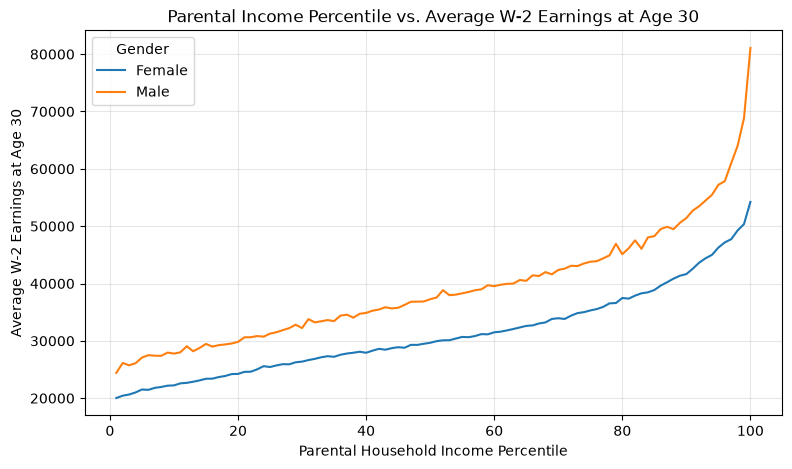

In [20]:
plt.figure(figsize=(9, 5))

sns.lineplot(
    data=oi,
    x="par_pctile",
    y="w2wages_30_f",
    label="Female"
)

sns.lineplot(
    data=oi,
    x="par_pctile",
    y="w2wages_30_m",
    label="Male"
)

plt.title("Parental Income Percentile vs. Average W-2 Earnings at Age 30")
plt.xlabel("Parental Household Income Percentile")
plt.ylabel("Average W-2 Earnings at Age 30")
plt.legend(title="Gender")
plt.grid(alpha=0.3)

plt.show()

### Opportunity Insights Data Quality

The Opportunity Insights dataset contains 100 rows and 25 columns, with each row representing a parental income percentile rather than an individual person.

I checked the parental income percentile and adult wage variables used in my graph. There were no missing values, duplicate parental income percentiles, or negative wages. The parental income percentiles also ranged from 1 to 100 as expected.

I didn't find any issues that required cleaning for these variables, so I kept the original values for the analysis.

### Opportunity Insights: Parental Income and Adult Earnings

The graph shows that average W-2 earnings at age 30 generally increase as parental household income percentile increases. This pattern appears for both men and women, although men consistently have higher average earnings. The increase is especially noticeable at the highest parental income percentiles.

**So what?** This suggests that family economic background is associated with earnings later in life. It also shows differences between men and women, which could be worth investigating further.

**Expected or unexpected?** I expected people from higher-income families to have higher earnings as adults, but I was surprised by how sharply earnings increased near the highest parental income percentiles.

**What next?** I would compare this pattern with our primary datasets to see whether they show similar relationships between family background and adult economic outcomes. I would also look into how education and employment might help explain these differences.

### Connection to Our Research Question

Our project's main research question is how strongly early childhood family income and parental education levels predict adult earnings and employment status.

The Opportunity Insights dataset helps us explore the income portion of this question. Our graph shows that average W-2 earnings at age 30 generally increase as parental household income percentile increases. This suggests that family income is associated with adult earnings.

The ELS dataset adds another perspective by looking at employment outcomes across parental socioeconomic groups. We found that the low-SES group had higher unemployment percentages than the middle- and high-SES groups, even among people with postsecondary degrees.

These findings are relevant to our primary PSID and NLSY97 analyses because they examine similar relationships between family background and adult outcomes. However, the secondary datasets use aggregated statistics rather than individual records, so we cannot directly compare their values with individual-level survey observations.

The next step is to compare these patterns with the relationships identified in PSID and NLSY97 to see whether the findings are consistent across datasets.

### Consistency With Our Data Acquisition Plan

Our analysis follows the overall data acquisition plan because we used Opportunity Insights and ELS as secondary datasets to support our research on family background and adult economic outcomes.

For Opportunity Insights, we focused on parental income percentile and average W-2 earnings at age 30. For ELS, we compared unemployment percentages across parental socioeconomic groups and educational attainment categories.

We did not change our selected datasets, but we narrowed the analysis to variables that were available and relevant to our research question. These datasets provide supporting evidence rather than replacing our primary PSID and NLSY97 analyses.